<a href="https://colab.research.google.com/github/MaithiliTChowta/0683-CI-2026-27/blob/main/Flight_Price_EDA_Feature_Engineer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import libraries and load dataset




In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/Clean_Dataset.csv")

print("Dataset loaded successfully")

Dataset loaded successfully


2. Display first five and last five records

In [4]:
print("First five records:")
display(df.head())

print("Last five records:")
display(df.tail())

First five records:


,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


Last five records:


,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585


3. Check shape, columns and data types

In [5]:
print("Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types and Non-Null Counts:")
df.info()

Shape: (300153, 12)

Column Names:
Index(['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time',
       'stops', 'arrival_time', 'destination_city', 'class', 'duration',
       'days_left', 'price'],
      dtype='object')

Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64

4. Descriptive statistics

In [16]:
print("Descriptive Statistics:")
display(df.describe())



Descriptive Statistics:


,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


Task 2 – Data Quality Assessment

In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64


Check inconsistent values

In [9]:
for col in df.select_dtypes(include="object").columns:
    print("\n", col)
    print(df[col].value_counts(dropna=False))


 airline
airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64

 flight
flight
UK-706     3235
UK-772     2741
UK-720     2650
UK-836     2542
UK-822     2468
           ... 
6E-2914       1
G8-107        1
SG-9974       1
6E-865        1
SG-8339       1
Name: count, Length: 1561, dtype: int64

 source_city
source_city
Delhi        61343
Mumbai       60896
Bangalore    52061
Kolkata      46347
Hyderabad    40806
Chennai      38700
Name: count, dtype: int64

 departure_time
departure_time
Morning          71146
Early_Morning    66790
Evening          65102
Night            48015
Afternoon        47794
Late_Night        1306
Name: count, dtype: int64

 stops
stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64

 arrival_time
arrival_time
Night            91538
Evening          78323
Morning          62735
Afternoon        38139
Early_Morning   

Check price outliers

count    300153.000000
mean      20889.660523
std       22697.767366
min        1105.000000
25%        4783.000000
50%        7425.000000
75%       42521.000000
max      123071.000000
Name: price, dtype: float64


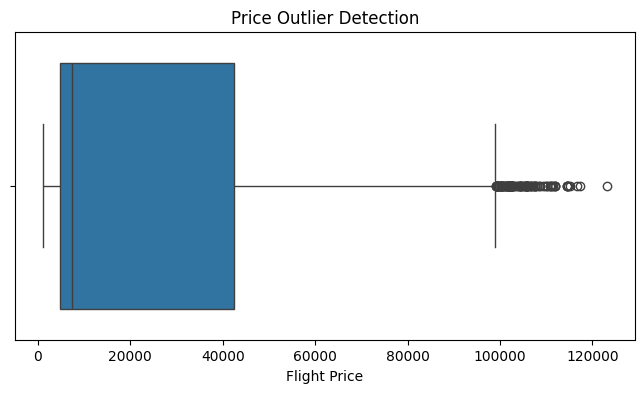

In [11]:
print(df["price"].describe())

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["price"])

plt.title("Price Outlier Detection")
plt.xlabel("Flight Price")
plt.show()

Check price distribution

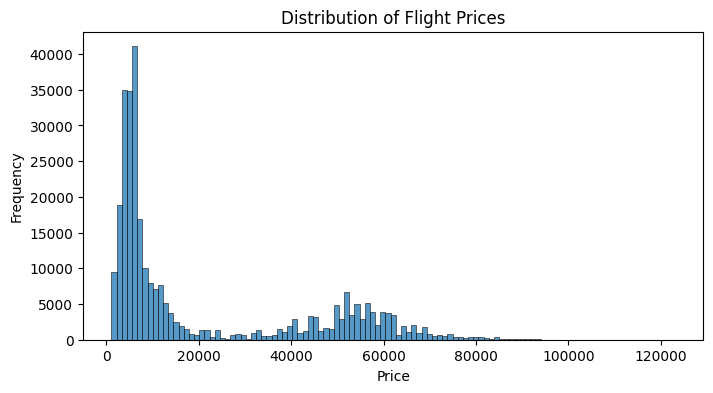

In [13]:
plt.figure(figsize=(8, 4))
sns.histplot(df["price"])
plt.title("Distribution of Flight Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

Document data-quality decisions

In [14]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Unnamed: 0          0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64


In [15]:
print("\nPrice minimum:", df["price"].min())
print("Price maximum:", df["price"].max())
print("Price average:", df["price"].mean())


Price minimum: 1105
Price maximum: 123071
Price average: 20889.660523133203


Task 3 – Exploratory Data Analysis (EDA)

Analyze Price distribution

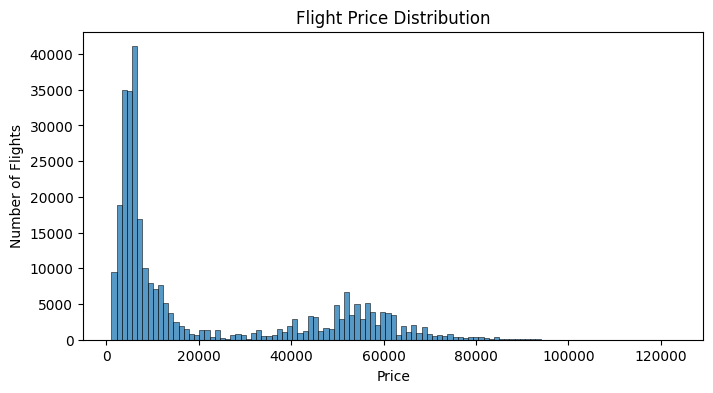

In [18]:
plt.figure(figsize=(8, 4))
sns.histplot(df["price"])
plt.title("Flight Price Distribution")
plt.xlabel("Price")
plt.ylabel("Number of Flights")
plt.show()

Number of flights by Airline

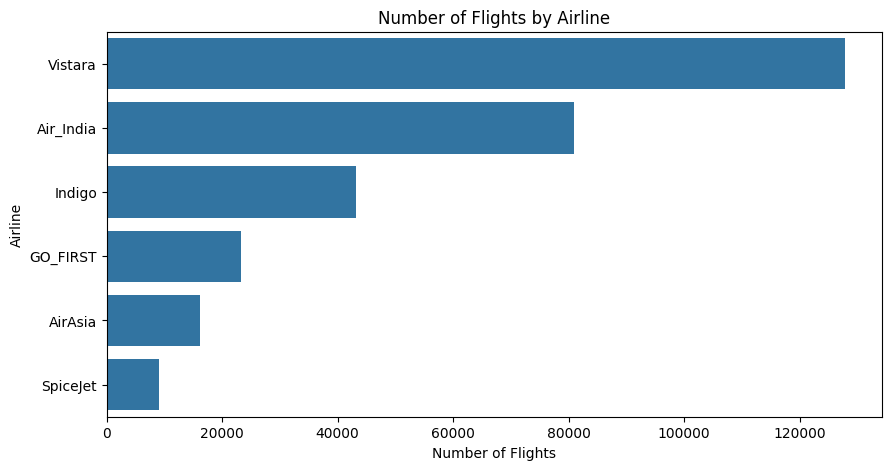

In [20]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y="airline",
              order=df["airline"].value_counts().index)
plt.title("Number of Flights by Airline")
plt.xlabel("Number of Flights")
plt.ylabel("Airline")
plt.show()

Average price by Airline

airline
AirAsia       4091.072742
Air_India    23507.019112
GO_FIRST      5652.007595
Indigo        5324.216303
SpiceJet      6179.278881
Vistara      30396.536302
Name: price, dtype: float64


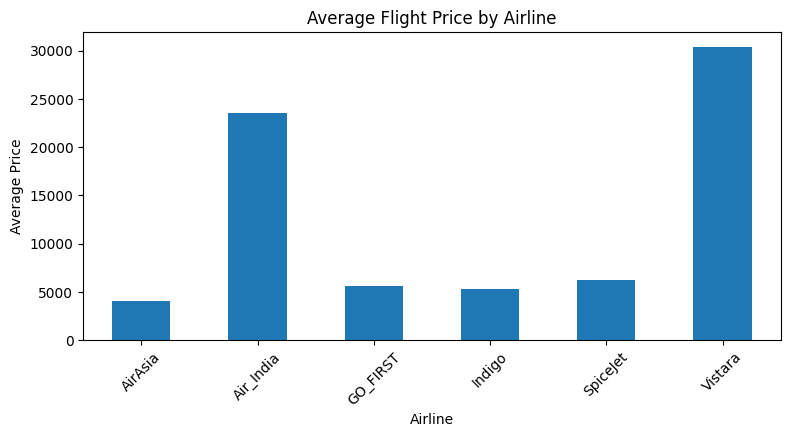

In [22]:
airline_price = df.groupby("airline")["price"].mean()

print(airline_price)

airline_price.plot(kind="bar", figsize=(9, 4))
plt.title("Average Flight Price by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

Compare prices across Source cities

source_city
Bangalore    21469.460575
Chennai      21995.339871
Delhi        18951.326639
Hyderabad    20155.623879
Kolkata      21746.235679
Mumbai       21483.818839
Name: price, dtype: float64


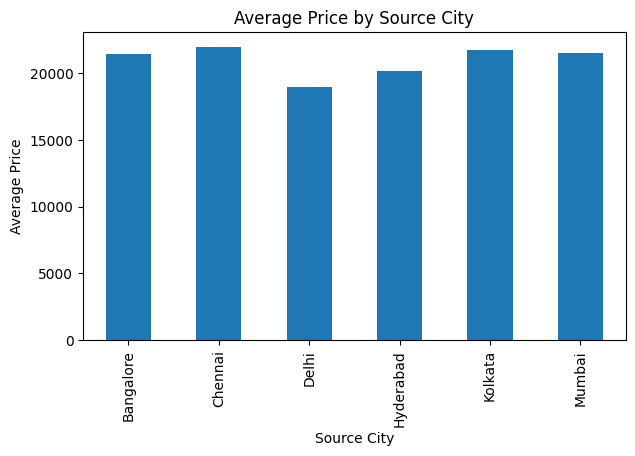

In [25]:
source_price = df.groupby("source_city")["price"].mean()

print(source_price)

source_price.plot(kind="bar", figsize=(7, 4))
plt.title("Average Price by Source City")
plt.xlabel("Source City")
plt.ylabel("Average Price")
plt.show()

Compare prices across Destination cities

destination_city
Bangalore    21593.955784
Chennai      21953.323969
Delhi        18436.767870
Hyderabad    20427.661284
Kolkata      21959.557556
Mumbai       21372.529469
Name: price, dtype: float64


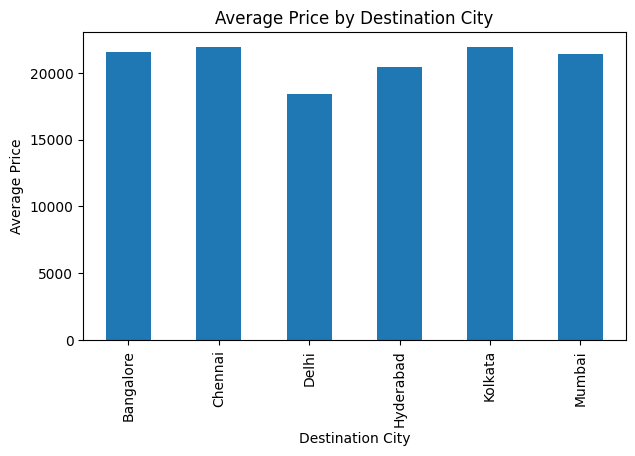

In [27]:
destination_price = df.groupby("destination_city")["price"].mean()

print(destination_price)

destination_price.plot(kind="bar", figsize=(7, 4))
plt.title("Average Price by Destination City")
plt.xlabel("Destination City")
plt.ylabel("Average Price")
plt.show()

Relationship between Total Stops and Price

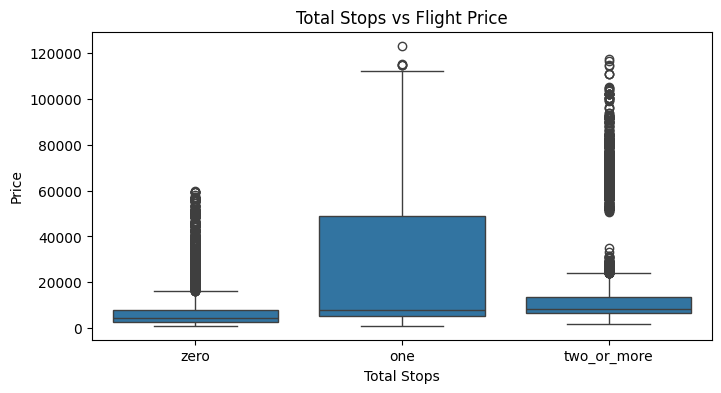

In [29]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="stops", y="price")
plt.title("Total Stops vs Flight Price")
plt.xlabel("Total Stops")
plt.ylabel("Price")
plt.show()

Journey date and month vs Price

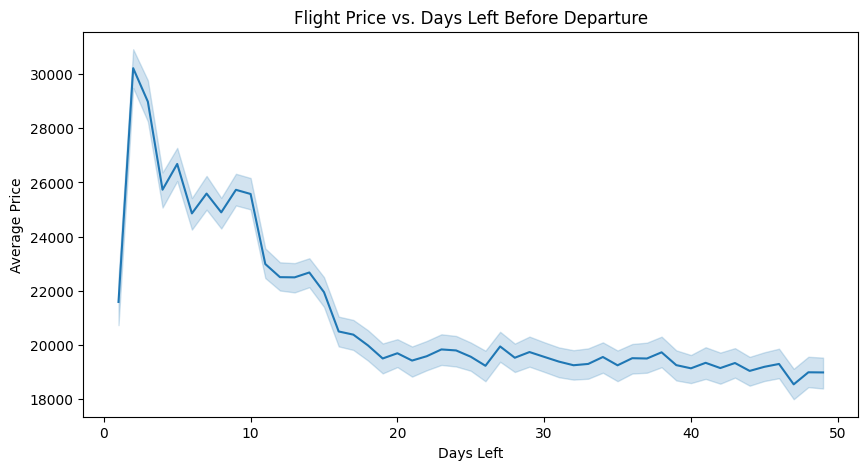

In [31]:
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x="days_left", y="price")
plt.title("Flight Price vs. Days Left Before Departure")
plt.xlabel("Days Left")
plt.ylabel("Average Price")
plt.show()

Departure time vs Price

departure_time
Early_Morning    20370.676718
Morning          21630.760254
Afternoon        18179.203331
Evening          21232.361894
Night            23062.146808
Late_Night        9295.299387
Name: price, dtype: float64


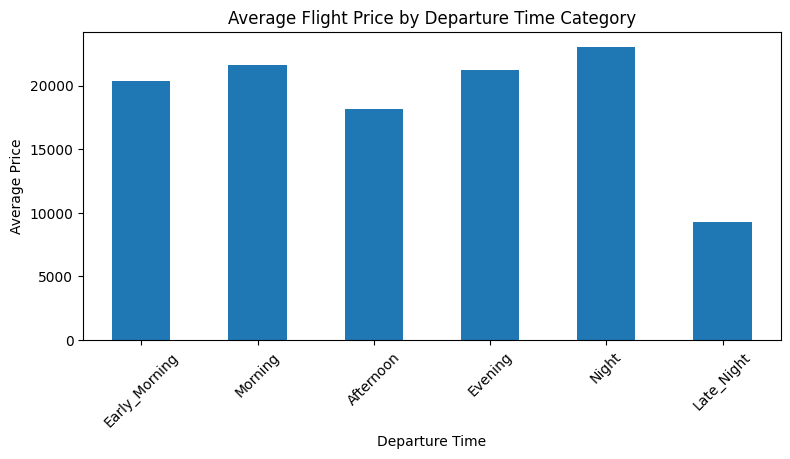

In [33]:
dep_price = df.groupby("departure_time")["price"].mean().reindex([
    "Early_Morning", "Morning", "Afternoon", "Evening", "Night", "Late_Night"
], fill_value=0)

print(dep_price)

dep_price.plot(kind="bar", figsize=(9, 4))
plt.title("Average Flight Price by Departure Time Category")
plt.xlabel("Departure Time")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

Arrival time vs Price

arrival_time
Early_Morning    14993.139521
Morning          22231.076098
Afternoon        18494.598993
Evening          23044.371615
Night            21586.758341
Late_Night       11284.906078
Name: price, dtype: float64


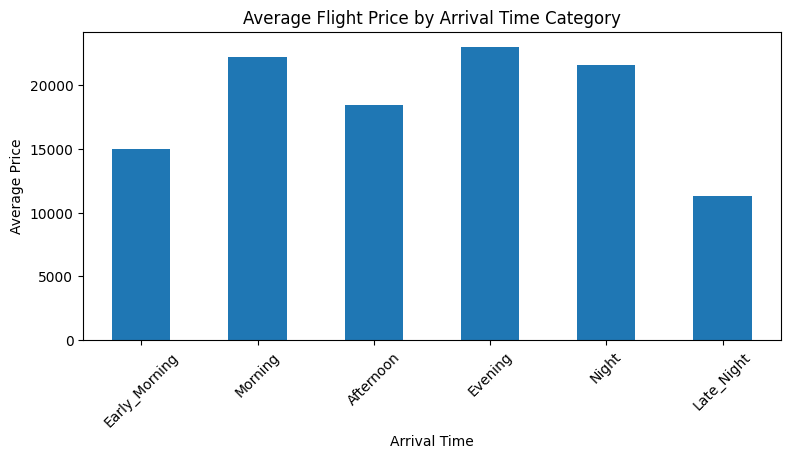

In [35]:
arrival_price = df.groupby("arrival_time")["price"].mean().reindex([
    "Early_Morning", "Morning", "Afternoon", "Evening", "Night", "Late_Night"
], fill_value=0)

print(arrival_price)

arrival_price.plot(kind="bar", figsize=(9, 4))
plt.title("Average Flight Price by Arrival Time Category")
plt.xlabel("Arrival Time")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

Duration vs Price

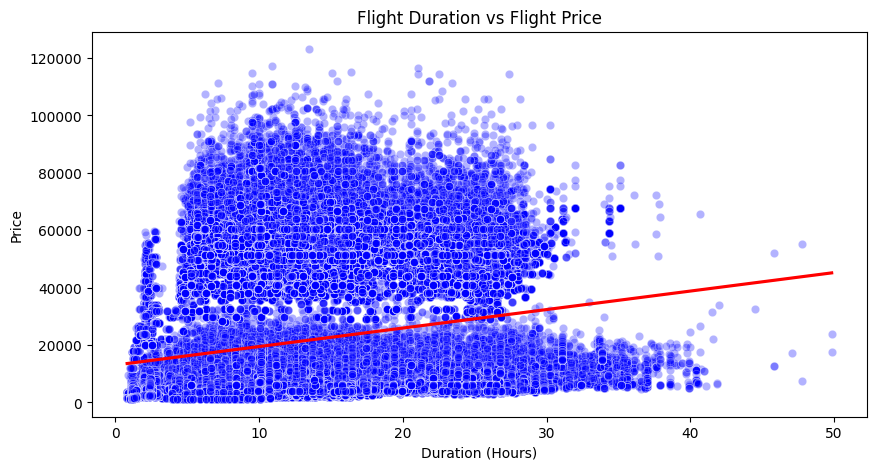

In [36]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="duration", y="price", alpha=0.3, color="blue")
sns.regplot(data=df, x="duration", y="price", scatter=False, color="red")
plt.title("Flight Duration vs Flight Price")
plt.xlabel("Duration (Hours)")
plt.ylabel("Price")
plt.show()

Task 4 – Date and Time Feature Engineering

Check the available date and time columns




In [68]:
# Display the available columns
print("Available columns:")
print(df.columns.tolist())

# Check whether the original assignment's columns exist
required_columns = ['Date_of_Journey', 'Dep_Time', 'Arrival_Time']

for col in required_columns:
    if col in df.columns:
        print(f"{col} is available")
    else:
        print(f"{col} is not available in this dataset")

Available columns:
['Unnamed: 0', 'duration', 'days_left', 'price', 'stops_numeric', 'duration_minutes', 'airline_AirAsia', 'airline_Air_India', 'airline_GO_FIRST', 'airline_Indigo', 'airline_SpiceJet', 'airline_Vistara', 'flight_6E-102', 'flight_6E-105', 'flight_6E-113', 'flight_6E-121', 'flight_6E-123', 'flight_6E-126', 'flight_6E-128', 'flight_6E-131', 'flight_6E-132', 'flight_6E-134', 'flight_6E-135', 'flight_6E-136', 'flight_6E-138', 'flight_6E-139', 'flight_6E-146', 'flight_6E-148', 'flight_6E-149', 'flight_6E-151', 'flight_6E-152', 'flight_6E-153', 'flight_6E-154', 'flight_6E-156', 'flight_6E-157', 'flight_6E-161', 'flight_6E-164', 'flight_6E-165', 'flight_6E-168', 'flight_6E-171', 'flight_6E-172', 'flight_6E-176', 'flight_6E-177', 'flight_6E-179', 'flight_6E-181', 'flight_6E-183', 'flight_6E-184', 'flight_6E-186', 'flight_6E-188', 'flight_6E-192', 'flight_6E-193', 'flight_6E-198', 'flight_6E-199', 'flight_6E-2001', 'flight_6E-2005', 'flight_6E-2007', 'flight_6E-2008', 'flight_6

Extract departure hour and minute


In [70]:
# The original 'departure_time' and 'arrival_time' columns were replaced during One-Hot Encoding.
# Here is how you can inspect the newly created time columns instead:

# Filter columns related to departure and arrival times
dep_cols = [col for col in df.columns if col.startswith('departure_time_')]
arr_cols = [col for col in df.columns if col.startswith('arrival_time_')]

print("One-hot encoded Departure Time columns found:")
print(dep_cols)

print("\nOne-hot encoded Arrival Time columns found:")
print(arr_cols)

print("\nPreview of timeline and encoded time values:")
display(df[['days_left'] + dep_cols[:3] + arr_cols[:3]].head())

One-hot encoded Departure Time columns found:
['departure_time_Afternoon', 'departure_time_Early_Morning', 'departure_time_Evening', 'departure_time_Late_Night', 'departure_time_Morning', 'departure_time_Night']

One-hot encoded Arrival Time columns found:
['arrival_time_Afternoon', 'arrival_time_Early_Morning', 'arrival_time_Evening', 'arrival_time_Late_Night', 'arrival_time_Morning', 'arrival_time_Night']

Preview of timeline and encoded time values:


,days_left,departure_time_Afternoon,departure_time_Early_Morning,departure_time_Evening,arrival_time_Afternoon,arrival_time_Early_Morning,arrival_time_Evening
0,1,0,0,1,0,0,0
1,1,0,1,0,0,0,0
2,1,0,1,0,0,1,0
3,1,0,0,0,1,0,0
4,1,0,0,0,0,0,0


Extract arrival hour and minute

In [71]:
# Convert duration from hours to minutes
df['duration_minutes'] = df['duration'] * 60

# Validate the new feature
print(df[['duration', 'duration_minutes']].head())

print("\nDuration minutes summary:")
print(df['duration_minutes'].describe())

# Check for invalid values
print("Negative duration values:",
      (df['duration_minutes'] < 0).sum())

   duration  duration_minutes
0      2.17             130.2
1      2.33             139.8
2      2.17             130.2
3      2.25             135.0
4      2.33             139.8

Duration minutes summary:
count    300153.000000
mean        733.261249
std         431.519834
min          49.800000
25%         409.800000
50%         675.000000
75%         970.200000
max        2989.800000
Name: duration_minutes, dtype: float64
Negative duration values: 0


Validate and remove original columns

In [41]:
# Since raw datetime columns do not exist in this clean dataset,
# let's look at the actual columns available, including 'stops_numeric'.

print("Actual columns in dataframe:")
print(df.columns.tolist())

print("\nSummary of numerical columns:")
print(df.describe())

print("\nDataFrame preview:")
df.head()

Actual columns in dataframe:
['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price', 'stops_numeric']

Summary of numerical columns:
          Unnamed: 0       duration      days_left          price  \
count  300153.000000  300153.000000  300153.000000  300153.000000   
mean   150076.000000      12.221021      26.004751   20889.660523   
std     86646.852011       7.191997      13.561004   22697.767366   
min         0.000000       0.830000       1.000000    1105.000000   
25%     75038.000000       6.830000      15.000000    4783.000000   
50%    150076.000000      11.250000      26.000000    7425.000000   
75%    225114.000000      16.170000      38.000000   42521.000000   
max    300152.000000      49.830000      49.000000  123071.000000   

       stops_numeric  
count  300153.000000  
mean        0.924312  
std         0.398106  
min         0.000000  
25%         1.000000  
50%   

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price,stops_numeric
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953,0
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953,0
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956,0
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955,0
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955,0


Task 5 – Stops and Duration Transformation

two_or_more

In [72]:
print(df['duration'].describe())

df['duration'] = pd.to_numeric(df['duration'], errors='coerce')

print("\nMissing Values:")
print(df['duration'].isnull().sum())

count    300153.000000
mean         12.221021
std           7.191997
min           0.830000
25%           6.830000
50%          11.250000
75%          16.170000
max          49.830000
Name: duration, dtype: float64

Missing Values:
0


Inspect distinct stop values

In [76]:
print(df.columns.tolist())

['Unnamed: 0', 'duration', 'days_left', 'price', 'stops_numeric', 'duration_minutes', 'airline_AirAsia', 'airline_Air_India', 'airline_GO_FIRST', 'airline_Indigo', 'airline_SpiceJet', 'airline_Vistara', 'flight_6E-102', 'flight_6E-105', 'flight_6E-113', 'flight_6E-121', 'flight_6E-123', 'flight_6E-126', 'flight_6E-128', 'flight_6E-131', 'flight_6E-132', 'flight_6E-134', 'flight_6E-135', 'flight_6E-136', 'flight_6E-138', 'flight_6E-139', 'flight_6E-146', 'flight_6E-148', 'flight_6E-149', 'flight_6E-151', 'flight_6E-152', 'flight_6E-153', 'flight_6E-154', 'flight_6E-156', 'flight_6E-157', 'flight_6E-161', 'flight_6E-164', 'flight_6E-165', 'flight_6E-168', 'flight_6E-171', 'flight_6E-172', 'flight_6E-176', 'flight_6E-177', 'flight_6E-179', 'flight_6E-181', 'flight_6E-183', 'flight_6E-184', 'flight_6E-186', 'flight_6E-188', 'flight_6E-192', 'flight_6E-193', 'flight_6E-198', 'flight_6E-199', 'flight_6E-2001', 'flight_6E-2005', 'flight_6E-2007', 'flight_6E-2008', 'flight_6E-2009', 'flight_6E

In [77]:
df = pd.read_csv("Clean_Dataset.csv")

print(df.columns.tolist())
print(df["stops"].value_counts(dropna=False))

['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']
stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64


Check malformed duration values

In [78]:
# The column name in this dataset is 'duration' (measured in hours).
# We can check for missing values and describe the hours first:
print("Missing 'duration' values:")
print(df["duration"].isnull().sum())

print("\nSummary of 'duration' (in hours):")
print(df["duration"].describe())

# To analyze in minutes as originally planned, we can create a temporary minutes column:
df["duration_minutes"] = df["duration"] * 60
print("\nSummary of 'duration_minutes' (in minutes):")
print(df["duration_minutes"].describe())

Missing 'duration' values:
0

Summary of 'duration' (in hours):
count    300153.000000
mean         12.221021
std           7.191997
min           0.830000
25%           6.830000
50%          11.250000
75%          16.170000
max          49.830000
Name: duration, dtype: float64

Summary of 'duration_minutes' (in minutes):
count    300153.000000
mean        733.261249
std         431.519834
min          49.800000
25%         409.800000
50%         675.000000
75%         970.200000
max        2989.800000
Name: duration_minutes, dtype: float64


Task 6 – Categorical Feature Encoding

In [5]:
import pandas as pd

df = pd.read_csv("Clean_Dataset.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   Unnamed: 0   airline   flight source_city departure_time stops  \
0           0  SpiceJet  SG-8709       Delhi        Evening  zero   
1           1  SpiceJet  SG-8157       Delhi  Early_Morning  zero   
2           2   AirAsia   I5-764       Delhi  Early_Morning  zero   
3           3   Vistara   UK-995       Delhi        Morning  zero   
4           4   Vistara   UK-963       Delhi        Morning  zero   

    arrival_time destination_city    class  duration  days_left  price  
0          Night           Mumbai  Economy      2.17          1   5953  
1        Morning           Mumbai  Economy      2.33          1   5953  
2  Early_Morning           Mumbai  Economy      2.17          1   5956  
3      Afternoon           Mumbai  Economy      2.25          1   5955  
4        Morning           Mumbai  Economy      2.33          1   5955  


Identify categorical columns

In [6]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

print("Categorical Columns:")
print(categorical_columns)

Categorical Columns:
Index(['airline', 'flight', 'source_city', 'departure_time', 'stops',
       'arrival_time', 'destination_city', 'class'],
      dtype='object')


Apply One-Hot Encoding

In [7]:
df = pd.get_dummies(
    df,
    columns=list(categorical_columns),
    dtype=int
)

print("Encoded Dataset:")
display(df.head())

Encoded Dataset:


,Unnamed: 0,duration,days_left,price,airline_AirAsia,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,...,arrival_time_Morning,arrival_time_Night,destination_city_Bangalore,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai,class_Business,class_Economy
0,0,2.17,1,5953,0,0,0,0,1,0,...,0,1,0,0,0,0,0,1,0,1
1,1,2.33,1,5953,0,0,0,0,1,0,...,1,0,0,0,0,0,0,1,0,1
2,2,2.17,1,5956,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,1
3,3,2.25,1,5955,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,1
4,4,2.33,1,5955,0,0,0,0,0,1,...,1,0,0,0,0,0,0,1,0,1


Display encoded data


In [8]:
print("Sample of Encoded Data:")
display(df.head(10))

Sample of Encoded Data:


,Unnamed: 0,duration,days_left,price,airline_AirAsia,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,...,arrival_time_Morning,arrival_time_Night,destination_city_Bangalore,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai,class_Business,class_Economy
0,0,2.17,1,5953,0,0,0,0,1,0,...,0,1,0,0,0,0,0,1,0,1
1,1,2.33,1,5953,0,0,0,0,1,0,...,1,0,0,0,0,0,0,1,0,1
2,2,2.17,1,5956,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,1
3,3,2.25,1,5955,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,1
4,4,2.33,1,5955,0,0,0,0,0,1,...,1,0,0,0,0,0,0,1,0,1
5,5,2.33,1,5955,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,1
6,6,2.08,1,6060,0,0,0,0,0,1,...,1,0,0,0,0,0,0,1,0,1
7,7,2.17,1,6060,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,1
8,8,2.17,1,5954,0,0,1,0,0,0,...,1,0,0,0,0,0,0,1,0,1
9,9,2.25,1,5954,0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,1


Task 7 – Final Dataset Validation

Display first five records

In [9]:
print("Final Dataset:")
display(df.head())

Final Dataset:


,Unnamed: 0,duration,days_left,price,airline_AirAsia,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,...,arrival_time_Morning,arrival_time_Night,destination_city_Bangalore,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai,class_Business,class_Economy
0,0,2.17,1,5953,0,0,0,0,1,0,...,0,1,0,0,0,0,0,1,0,1
1,1,2.33,1,5953,0,0,0,0,1,0,...,1,0,0,0,0,0,0,1,0,1
2,2,2.17,1,5956,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,1
3,3,2.25,1,5955,0,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,1
4,4,2.33,1,5955,0,0,0,0,0,1,...,1,0,0,0,0,0,0,1,0,1


Check shape

In [10]:
print("Final Dataset Shape:")
print(df.shape)

Final Dataset Shape:
(300153, 1600)


Check column names

In [51]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Unnamed: 0', 'duration', 'days_left', 'price', 'stops_numeric', 'duration_minutes', 'airline_AirAsia', 'airline_Air_India', 'airline_GO_FIRST', 'airline_Indigo', 'airline_SpiceJet', 'airline_Vistara', 'flight_6E-102', 'flight_6E-105', 'flight_6E-113', 'flight_6E-121', 'flight_6E-123', 'flight_6E-126', 'flight_6E-128', 'flight_6E-131', 'flight_6E-132', 'flight_6E-134', 'flight_6E-135', 'flight_6E-136', 'flight_6E-138', 'flight_6E-139', 'flight_6E-146', 'flight_6E-148', 'flight_6E-149', 'flight_6E-151', 'flight_6E-152', 'flight_6E-153', 'flight_6E-154', 'flight_6E-156', 'flight_6E-157', 'flight_6E-161', 'flight_6E-164', 'flight_6E-165', 'flight_6E-168', 'flight_6E-171', 'flight_6E-172', 'flight_6E-176', 'flight_6E-177', 'flight_6E-179', 'flight_6E-181', 'flight_6E-183', 'flight_6E-184', 'flight_6E-186', 'flight_6E-188', 'flight_6E-192', 'flight_6E-193', 'flight_6E-198', 'flight_6E-199', 'flight_6E-2001', 'flight_6E-2005', 'flight_6E-2007', 'flight_6E-2008', 'flight_6E-200

Check data types

In [52]:
print("Data Types:")
print(df.dtypes)

Data Types:
Unnamed: 0                      int64
duration                      float64
days_left                       int64
price                           int64
stops_numeric                   int64
                               ...   
destination_city_Hyderabad      int64
destination_city_Kolkata        int64
destination_city_Mumbai         int64
class_Business                  int64
class_Economy                   int64
Length: 1602, dtype: object


Check missing values

In [53]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Unnamed: 0                    0
duration                      0
days_left                     0
price                         0
stops_numeric                 0
                             ..
destination_city_Hyderabad    0
destination_city_Kolkata      0
destination_city_Mumbai       0
class_Business                0
class_Economy                 0
Length: 1602, dtype: int64


Check remaining object columns



In [11]:
print("Object Columns:")
print(df.select_dtypes(include="object").columns)

Object Columns:
Index([], dtype='object')


Identify input features and target variable

In [12]:
X = df.drop("price", axis=1)

y = df["price"]

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nNumber of Input Features:", X.shape[1])

Input Features:
   Unnamed: 0  duration  days_left  airline_AirAsia  airline_Air_India  \
0           0      2.17          1                0                  0   
1           1      2.33          1                0                  0   
2           2      2.17          1                1                  0   
3           3      2.25          1                0                  0   
4           4      2.33          1                0                  0   

   airline_GO_FIRST  airline_Indigo  airline_SpiceJet  airline_Vistara  \
0                 0               0                 1                0   
1                 0               0                 1                0   
2                 0               0                 0                0   
3                 0               0                 0                1   
4                 0               0                 0                1   

   flight_6E-102  ...  arrival_time_Morning  arrival_time_Night  \
0              0  ...      

Save final dataset

In [13]:
df.to_csv("Flight_Price_Cleaned.csv", index=False)

print("Final dataset saved successfully!")

Final dataset saved successfully!
